# 방향은 배경에 얼마나 기대나 — 배경을 끄고 켜서 비교 (실녹음)

> 2026-10-28 · 녹음 `T2_fpv`, `T_fpv` (Step8d T 측정) · 계산: [`doa/doa_stream.py`](../doa/doa_stream.py), [`doa/mask_phat.py`](../doa/mask_phat.py) · 앞 노트북 [`doa_mask_real.ipynb`](doa_mask_real.ipynb)의 A와 같은 계산 · 커널: `Tools/.venv`
> 결론은 마지막 절에 **결론 후보**로만 적는다.

**질문:** 보드 방향 계산([doa.c](../../Core/app/src/doa.c))은 배경을 두 군데 쓴다.
- **① 소리 있음 문:** 창 전력 ÷ 배경 전력 ≥ 6 dB일 때만 방향을 낸다
- **② 배경 빼기:** PHAT 전에 창 교차 스펙트럼 − 배경 교차 스펙트럼

배경이 없으면(①·② 끔) 방향 성능이 얼마나 나빠지나? ①과 ② 중 무엇이 효과를 내나?

| 이름 | ① 문 | ② 빼기 | 비고 |
|---|---|---|---|
| A 올바른 배경 | 켬 (올바른 배경) | 켬 (올바른 배경) | 앞 노트북 A와 같음 |
| B 빼기만 끔 | 켬 (올바른 배경) | 끔 | ②의 효과 = B − A |
| C 배경 없음 | 끔 (항상 소리 있음) | 끔 | 배경을 아예 안 배운 경우 |
| (보드) 틀린 배경 | 켬 (7 dB 큰 배경) | 켬 (같은 배경) | 보드가 실제로 낸 값, [snr_T.ipynb](snr_T.ipynb) 5절. 배경을 녹음 전에 배워 여기서 재계산 불가 |

**공통:** 대역 안 221칸, 관측 0.5 s, 이동 0.25 s, 블록 512, 채널 지연 보정. 유효 판정은 doa.h와 같다 (피크 ≥ 0.15, 닫힘 ≤ 0.3샘플, norm 0.5 ~ 1.3).
**성공** = 문 통과 · 유효 · 높은 SNR 구간 방위 중앙값과 ±10° 안. SNR = ch1 300 ~ 3000 Hz (창 − 바닥) ÷ 바닥, 2 dB 칸.
**조용할 때 오탐:** 재생 전 조용한 구간에서 방향을 낸 비율. 문을 끄면 이것이 늘 수 있다 (A·B는 배경을 배운 구간 자체라 낙관적인 값).
**한계:** 조용한 방, 음원 하나, FPV 재생. 현장의 바뀌는 잡음·방향성 잡음은 이 녹음에 없다.

In [1]:
import sys, warnings
import numpy as np, soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
sys.path.insert(0, ".."); sys.path.insert(0, "../doa")
import doa_stream as ds, gcc_phat as g
DELAY = ds.channel_delays_us()                     # mask_phat를 불러오면 채널 지연을 0으로 바꾸므로 먼저 보관
import mask_phat as mp
ds.DELAY_US = DELAY
FS = 12500
A = mp.args(); POS, D = ds.positions()
mp.FREQ_IN = (mp.FREQ >= 300) & (mp.FREQ <= 3000)
print("채널 지연 [us]:", np.round(DELAY, 1), "· 대역 칸", int(mp.FREQ_IN.sum()))

채널 지연 [us]: [  0.  -23.1   4.3] · 대역 칸 221


## 1. 녹음 불러오기, 올바른 배경

배경 = 녹음 시작 3 s 뒤부터 소리 시작 2 s 전까지 (앞 노트북과 같음). 조용한 구간 창(오탐 확인용)도 같은 범위에서 0.25 s 간격으로 뽑는다.

In [2]:
def band_p(seg):
    w = np.hanning(len(seg)); X = np.fft.rfft((seg - seg.mean()) * w); f = np.fft.rfftfreq(len(seg), 1 / FS)
    m = (f >= 300) & (f < 3000); return 2 * np.sum(np.abs(X[m]) ** 2) / (len(seg) * np.sum(w ** 2))
REC = {}
for lab in ("T2_fpv", "T_fpv"):
    x, fs = sf.read(f"../dumps/stream/{lab}/seg_000.wav", dtype="float64"); x = (x - x.mean(0)).T   # [3, N]
    t = np.arange(0, x.shape[1] / FS - 1, 0.5)
    L = np.array([10 * np.log10(2 * band_p(x[0, int(s * FS):int(s * FS) + FS]) + 1e-30) for s in t])
    fl0 = np.median(L[(t > 3) & (t < 12)]); hi = (t > 12) & (L > fl0 + 10)
    on = t[np.argmax(np.convolve(hi, np.ones(6, int), "full")[5:][:len(t)] == 6)]
    bg = ds.cross_spectra(x[:, int(3 * FS):int((on - 2) * FS)], A.block, mp.NFFT)
    N1 = np.median([band_p(x[0, int(s * FS):int(s * FS) + 6250]) for s in np.arange(3, on - 2.5, 0.25)])
    s0 = np.arange(int((on - 1) * FS), x.shape[1] - 6250 - FS, int(0.25 * FS))
    q0 = np.arange(int(3 * FS), int((on - 2) * FS) - 6250, int(0.25 * FS))     # 조용한 구간 창
    snr = np.array([10 * np.log10(max(band_p(x[0, s:s + 6250]) - N1, 1e-30) / N1) for s in s0])
    REC[lab] = dict(x=x, onset=on, bg=bg, s0=s0, q0=q0, snr=snr)
    print(f"{lab}: 소리 시작 {on:.1f} s, 배경 {on - 5:.1f} s 분량, 소리 창 {len(s0)}개, 조용한 창 {len(q0)}개")

T2_fpv: 소리 시작 32.0 s, 배경 27.0 s 분량, 소리 창 2650개, 조용한 창 106개


T_fpv: 소리 시작 24.5 s, 배경 19.5 s 분량, 소리 창 2613개, 조용한 창 76개


In [3]:
def run_window(x, s, bg):
    # 창 하나: 교차 스펙트럼은 한 번만 구하고 ② 빼기 켬/끔 두 결과를 낸다
    S = ds.cross_spectra(x[:, s:s + 6250], A.block, mp.NFFT)
    snr3 = 10 * np.log10(sum(S[3 + c][mp.FREQ_IN].sum() for c in range(3)).real / sum(bg[3 + c][mp.FREQ_IN].sum() for c in range(3)).real)
    mask = mp.make_mask(S, "full", None)
    out = {}
    for sub in (True, False):
        R = [S[k] - bg[k] if sub else S[k] for k in range(3)]
        cur = [mp.phat_curve(Rk, mask) for Rk in R]
        tau = [cur[k][2] - (DELAY[j] - DELAY[i]) * 1e-6 * FS for k, (i, j) in enumerate(g.PAIRS)]
        ang, norm = g.tdoa_to_angle(tau, FS, POS)
        r = dict(tau=tau, peak=[c[3] for c in cur], angle=ang, norm=norm, closure=tau[0] + tau[2] - tau[1], snr3=snr3)
        r["valid"] = ds.is_valid(r, A); r["curves"] = cur
        out[sub] = r
    return out

## 2. 창 하나 손으로 따라가기 — 같은 창, ② 빼기만 켜고 끄기

SNR 약 4 dB(소리가 바닥보다 조금 큰) 창 하나. 조용한 방의 바닥에는 보드 간섭(48.8 Hz 줄의 배수, 세 채널에 같이 들어감)이 있다.
**예상:** 빼기를 끄면 세 마이크에 동시에 들어오는 간섭이 "지연 0" 쪽으로 표를 모은다. 빼기를 켜면 그 표가 사라진다.

창 381.25 ~ 381.75 s, ch1 SNR 4.0 dB, 배경 대비 3.0 dB (문 ① 기준 6 dB)
  ② 빼기 켬: 봉우리 [0.2, 0.19, 0.18], 지연 [1.83, 1.52, -0.7] 샘플, 닫힘 -0.39, norm 0.79, 방위  -16.4°, 유효 False
  ② 빼기 끔: 봉우리 [0.51, 0.5, 0.61], 지연 [0.46, 0.1, -0.36] 샘플, 닫힘 -0.01, norm 0.19, 방위  -48.3°, 유효 False


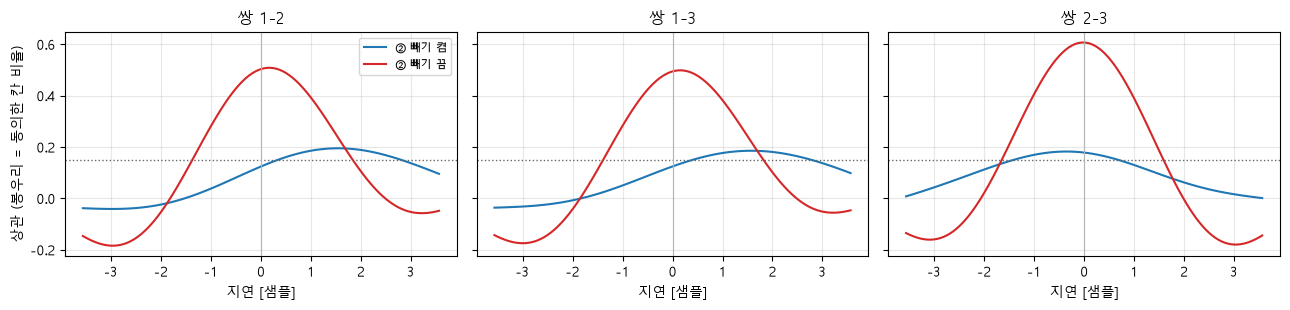

In [4]:
R = REC["T2_fpv"]; i = int(np.argmin(np.abs(R["snr"] - 4))); s = R["s0"][i]
rr = run_window(R["x"], s, R["bg"])
print(f"창 {s / FS:.2f} ~ {s / FS + 0.5:.2f} s, ch1 SNR {R['snr'][i]:.1f} dB, 배경 대비 {rr[True]['snr3']:.1f} dB (문 ① 기준 6 dB)")
for nm, r in (("② 빼기 켬", rr[True]), ("② 빼기 끔", rr[False])):
    print(f"  {nm}: 봉우리 {np.round(r['peak'], 2).tolist()}, 지연 {np.round(r['tau'], 2).tolist()} 샘플, 닫힘 {r['closure']:+.2f}, norm {r['norm']:.2f}, 방위 {r['angle']:6.1f}°, 유효 {r['valid']}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for k, a in enumerate(ax):
    for nm, r, c in (("② 빼기 켬", rr[True], "C0"), ("② 빼기 끔", rr[False], "C3")):
        a.plot(r["curves"][k][0], r["curves"][k][1], color=c, label=nm)
    a.axhline(0.15, color="0.4", ls=":", lw=1); a.axvline(0, color="0.7", lw=.8)
    a.set_title(f"쌍 {g.PAIRS[k][0] + 1}-{g.PAIRS[k][1] + 1}"); a.set_xlabel("지연 [샘플]"); a.grid(alpha=.3)
ax[0].set_ylabel("상관 (봉우리 = 동의한 칸 비율)"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. 전체 실행

소리 창 전부와 조용한 창 전부를 계산한다. 몇 분 걸린다.

In [5]:
OUT = {}
for lab, R in REC.items():
    OUT[lab] = dict(sig=[run_window(R["x"], s, R["bg"]) for s in R["s0"]],
                    quiet=[run_window(R["x"], s, R["bg"]) for s in R["q0"]])
    print(f"{lab}: 소리 {len(OUT[lab]['sig'])}창 · 조용 {len(OUT[lab]['quiet'])}창 완료")

T2_fpv: 소리 2650창 · 조용 106창 완료


T_fpv: 소리 2613창 · 조용 76창 완료


In [6]:
NAME = {"A": "A 올바른 배경", "B": "B 빼기만 끔", "C": "C 배경 없음"}
SUB = {"A": True, "B": False, "C": False}
def pick(rs, m):
    rs = [r[SUB[m]] for r in rs]
    ang = np.array([r["angle"] for r in rs]); val = np.array([r["valid"] for r in rs])
    gate = np.ones(len(rs), bool) if m == "C" else np.array([r["snr3"] >= 6.0 for r in rs])
    return ang, val, gate
def success(lab, m):
    ang, val, gate = pick(OUT[lab]["sig"], m); snr = REC[lab]["snr"]
    hi = val & gate & (snr >= 25)
    ref = np.degrees(np.angle(np.mean(np.exp(1j * np.radians(ang[hi])))))
    err = np.abs((ang - ref + 180) % 360 - 180)
    return gate & val & (err <= 10), gate & val & (err > 10), ref
BINS = np.arange(-6, 46, 2)
def curve(snr, ok):
    c, r, n = [], [], []
    for lo in BINS[:-1]:
        m = (snr >= lo) & (snr < lo + 2)
        if m.sum() >= 10: c.append(lo + 1); r.append(ok[m].mean()); n.append(m.sum())
    return np.array(c), np.array(r), np.array(n)
def cross(c, r, p):
    for i in range(len(c) - 1, 0, -1):
        if r[i] >= p > r[i - 1]: return c[i - 1] + (p - r[i - 1]) / (r[i] - r[i - 1]) * (c[i] - c[i - 1])
    return np.nan
def tstr(c, r, p):
    v = cross(c, r, p)
    if np.isfinite(v): return f"{v:.1f}"
    return f"< {c[0] - 1:.0f}" if np.all(r >= p) else (f"> {c[-1] + 1:.0f}" if np.all(r < p) else "?")

## 4. 성공률 곡선과 T

▶ **예측 지점 (T1)** — 아래 곡선을 보기 전에 대화에서 예측한다: C(배경 없음)의 T90은 A(12.4 dB)보다 얼마나 높을까?

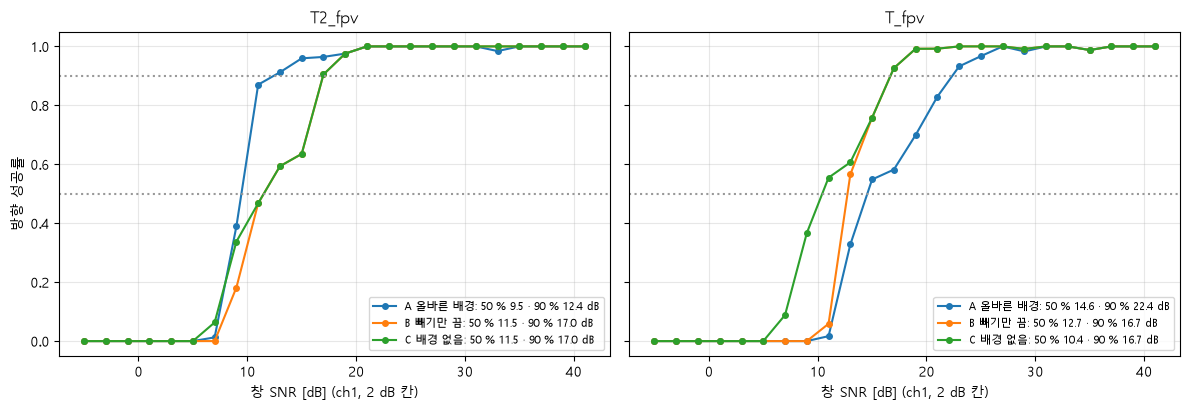

T2_fpv  A 올바른 배경    : 기준 방위  -12.7° · T50    9.5 · T90   12.4 dB · 낸 방향 중 오답(> 10°) 0/1131 = 0.0%
T2_fpv  B 빼기만 끔     : 기준 방위  -12.7° · T50   11.5 · T90   17.0 dB · 낸 방향 중 오답(> 10°) 0/1026 = 0.0%
T2_fpv  C 배경 없음     : 기준 방위  -12.7° · T50   11.5 · T90   17.0 dB · 낸 방향 중 오답(> 10°) 0/1043 = 0.0%
T_fpv   A 올바른 배경    : 기준 방위  -10.9° · T50   14.6 · T90   22.4 dB · 낸 방향 중 오답(> 10°) 1/1242 = 0.1%
T_fpv   B 빼기만 끔     : 기준 방위  -11.1° · T50   12.7 · T90   16.7 dB · 낸 방향 중 오답(> 10°) 1/1414 = 0.1%
T_fpv   C 배경 없음     : 기준 방위  -11.1° · T50   10.4 · T90   16.7 dB · 낸 방향 중 오답(> 10°) 1/1532 = 0.1%


In [7]:
RES = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for a, lab in zip(ax, REC):
    for m in "ABC":
        ok, wrong, ref = success(lab, m); c, r, n = curve(REC[lab]["snr"], ok)
        RES[(lab, m)] = (c, r, n, wrong, ok, ref)
        a.plot(c, r, "o-", ms=4, label=f"{NAME[m]}: 50 % {tstr(c, r, .5)} · 90 % {tstr(c, r, .9)} dB")
    a.axhline(.5, color="0.6", ls=":"); a.axhline(.9, color="0.6", ls=":")
    a.set_title(lab); a.set_xlabel("창 SNR [dB] (ch1, 2 dB 칸)"); a.grid(alpha=.3); a.legend(fontsize=8)
ax[0].set_ylabel("방향 성공률"); plt.tight_layout(); plt.show()
for (lab, m), (c, r, n, wrong, ok, ref) in RES.items():
    out = ok | wrong
    print(f"{lab:7s} {NAME[m]:12s}: 기준 방위 {ref:6.1f}° · T50 {tstr(c, r, .5):>6s} · T90 {tstr(c, r, .9):>6s} dB · 낸 방향 중 오답(> 10°) {wrong.sum()}/{out.sum()} = {wrong.sum() / max(out.sum(), 1):.1%}")

## 5. 무엇이 막았나, 조용할 때 무엇을 냈나

- 첫 셀: SNR 칸마다 문 통과율·유효율. 문을 끈 C에서 유효율이 낮으면 막은 것은 PHAT 자체(봉우리·닫힘·norm)다.
- 둘째 셀: 재생 전 조용한 구간에서 방향을 낸 비율과 그 방위. 문이 없으면 조용할 때도 무언가를 가리킬 수 있다.

In [8]:
for lab in REC:
    snr = REC[lab]["snr"]
    print(f"{lab}:")
    for lo in (0, 4, 8, 12, 16, 20):
        k = (snr >= lo) & (snr < lo + 4)
        row = []
        for m in "ABC":
            ang, val, gate = pick(OUT[lab]["sig"], m)
            row.append(f"{m} 문 {gate[k].mean():4.0%} · 유효 {val[k].mean():4.0%}")
        print(f"  SNR {lo:2d} ~ {lo + 4:2d} dB ({k.sum():3d}창): " + "  |  ".join(row))

T2_fpv:
  SNR  0 ~  4 dB (150창): A 문   0% · 유효  29%  |  B 문   0% · 유효   0%  |  C 문 100% · 유효   0%
  SNR  4 ~  8 dB (164창): A 문   1% · 유효  57%  |  B 문   1% · 유효   3%  |  C 문 100% · 유효   3%
  SNR  8 ~ 12 dB (154창): A 문  75% · 유효  80%  |  B 문  75% · 유효  40%  |  C 문 100% · 유효  40%
  SNR 12 ~ 16 dB (165창): A 문 100% · 유효  93%  |  B 문 100% · 유효  61%  |  C 문 100% · 유효  61%
  SNR 16 ~ 20 dB (166창): A 문 100% · 유효  97%  |  B 문 100% · 유효  94%  |  C 문 100% · 유효  94%
  SNR 20 ~ 24 dB (160창): A 문 100% · 유효 100%  |  B 문 100% · 유효 100%  |  C 문 100% · 유효 100%
T_fpv:
  SNR  0 ~  4 dB (205창): A 문   0% · 유효   0%  |  B 문   0% · 유효   0%  |  C 문 100% · 유효   0%
  SNR  4 ~  8 dB (223창): A 문   0% · 유효   4%  |  B 문   0% · 유효   4%  |  C 문 100% · 유효   4%
  SNR  8 ~ 12 dB (239창): A 문   6% · 유효  19%  |  B 문   6% · 유효  46%  |  C 문 100% · 유효  46%
  SNR 12 ~ 16 dB (246창): A 문  94% · 유효  45%  |  B 문  94% · 유효  68%  |  C 문 100% · 유효  68%
  SNR 16 ~ 20 dB (245창): A 문 100% · 유효  64%  |  B 문 100% · 유효  96%  |  C 문 100% · 유효 

In [9]:
for lab in REC:
    print(f"{lab} 조용한 구간 {len(REC[lab]['q0'])}창:")
    for m in "ABC":
        ang, val, gate = pick(OUT[lab]["quiet"], m); o = gate & val
        a = ang[o]
        desc = f"방위 중앙 {np.median(a):6.1f}°, 사분위 {np.percentile(a, 25):6.1f} ~ {np.percentile(a, 75):6.1f}°" if o.sum() else "-"
        print(f"  {NAME[m]:12s}: 방향을 낸 창 {o.sum():3d}/{len(o)} = {o.mean():5.1%} · {desc}")

T2_fpv 조용한 구간 106창:
  A 올바른 배경    : 방향을 낸 창   0/106 =  0.0% · -
  B 빼기만 끔     : 방향을 낸 창   0/106 =  0.0% · -
  C 배경 없음     : 방향을 낸 창   0/106 =  0.0% · -
T_fpv 조용한 구간 76창:
  A 올바른 배경    : 방향을 낸 창   0/76 =  0.0% · -
  B 빼기만 끔     : 방향을 낸 창   0/76 =  0.0% · -
  C 배경 없음     : 방향을 낸 창   0/76 =  0.0% · -


## 6. 결론 후보 (사용자 확인 전)

보드 값(틀린 배경, T90 24.3 dB) 대비 거리 배수 = 10^((24.3 − T) ÷ 20). 보드 값은 T2_fpv에서만 잰 값이라 T_fpv 줄의 배수는 참고만.

In [10]:
for (lab, m), (c, r, n, wrong, ok, ref) in RES.items():
    t90 = cross(c, r, .9); f = (f"×{10 ** ((24.3 - t90) / 20):.1f}" if np.isfinite(t90) else "-")
    out = ok | wrong
    ang, val, gate = pick(OUT[lab]["quiet"], m)
    print(f"{lab:7s} {NAME[m]:12s}: T50 {tstr(c, r, .5):>6s} dB · T90 {tstr(c, r, .9):>6s} dB (보드 대비 거리 {f}) · 오답률 {wrong.sum() / max(out.sum(), 1):.1%} · 조용할 때 방향 냄 {(gate & val).mean():.1%}  (근거 4·5절)")
print()
print("아직 모르는 것: 바뀌는 잡음·방향성 잡음(도로, 바람)이 있을 때. 이 녹음은 조용한 방이라 배경이 거의 일정하다.")

T2_fpv  A 올바른 배경    : T50    9.5 dB · T90   12.4 dB (보드 대비 거리 ×3.9) · 오답률 0.0% · 조용할 때 방향 냄 0.0%  (근거 4·5절)
T2_fpv  B 빼기만 끔     : T50   11.5 dB · T90   17.0 dB (보드 대비 거리 ×2.3) · 오답률 0.0% · 조용할 때 방향 냄 0.0%  (근거 4·5절)
T2_fpv  C 배경 없음     : T50   11.5 dB · T90   17.0 dB (보드 대비 거리 ×2.3) · 오답률 0.0% · 조용할 때 방향 냄 0.0%  (근거 4·5절)
T_fpv   A 올바른 배경    : T50   14.6 dB · T90   22.4 dB (보드 대비 거리 ×1.2) · 오답률 0.1% · 조용할 때 방향 냄 0.0%  (근거 4·5절)
T_fpv   B 빼기만 끔     : T50   12.7 dB · T90   16.7 dB (보드 대비 거리 ×2.4) · 오답률 0.1% · 조용할 때 방향 냄 0.0%  (근거 4·5절)
T_fpv   C 배경 없음     : T50   10.4 dB · T90   16.7 dB (보드 대비 거리 ×2.4) · 오답률 0.1% · 조용할 때 방향 냄 0.0%  (근거 4·5절)

아직 모르는 것: 바뀌는 잡음·방향성 잡음(도로, 바람)이 있을 때. 이 녹음은 조용한 방이라 배경이 거의 일정하다.
